# Снижение активности по картам: кто, насколько и за счёт чего

**Автор: Никитенко Софья**
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

clients = pd.read_csv("clean_clients.csv")
txn     = pd.read_csv("clean_txn.csv")

for col in ["birth_date", "registration_date", "card_open_date", "app_last_login"]:
    clients[col] = pd.to_datetime(clients[col], errors="coerce")
txn["txn_datetime"] = pd.to_datetime(txn["txn_datetime"], errors="coerce")

## 1. Главное

1. Среднемесячное число успешных транзакций на клиента упало на 10,4 % при сравнении 1-го полугодия 2024 с 1-м полугодием 2025 (31 220 → 27 985 операций в месяц). При этом активных клиентов стало на 4,6 % больше (4 748 → 4 968). Проблема не в оттоке, а в интенсивности использования карты.
2. 1 753 из 2 379 клиентов, определенных метрикой активности клиентов снизили активность. 
3. Канал «Карта» потерял порядка 20 тыс. операций в месяц — это основной источник падения. Рост «Токена» его не компенсирует.
4. Четыре группы кампании — без приложения (733), пенсионеры (200), базовый уровень (578) и продвинутые уровни (242) — покрывают всех 1 753 целевых клиентов со снижением активности.

## 2. Контекст

<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->

Отчёт поддерживает решение о запуске адресной кампании по возврату активности клиентов-держателей карт банка «Меридиан» в 1-м полугодии 2025. Бизнес-вопрос: почему клиенты стали реже платить картой, кто именно снизил активность и на какие группы разделить кампанию. Результат — сегментация на 4 группы с правилами отбора. По этим группам маркетинг и продуктовая команда смогут запустить персональные акции, не тратя ресурс на клиентов, которые не снизили активность.

## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

Период анализа: 2024-01-01 — 2025-06-30. После очистки в работе 5 639 клиентов и 592 440 транзакций. Из расчёта метрики исключены:

клиенты, отсутствующие в справочнике (30 113 операций клиентов, ушедших из банка),

операции до открытия карты (1 шт.),

операции вне заявленного периода (90 шт.),

каналы «СБП» и «Онлайн-банк» — фокус на карте.

Метрика активности — среднемесячное количество успешных транзакций по каналу «Карта» на одного клиента, в двух окнах: базовое 2024 (12 месяцев) и оцениваемое H1 2025 (6 месяцев). Считается только для клиентов массового сегмента с согласием на маркетинг, у которых была хотя бы одна успешная транзакция в 2024 и нет перехода на использование Токенов.

Ограничение метрики: она не увидит снижение среднего чека. Дополнительно метрика не отражает переток в СБП и онлайн-банк — эти каналы вне фокуса.

## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. 

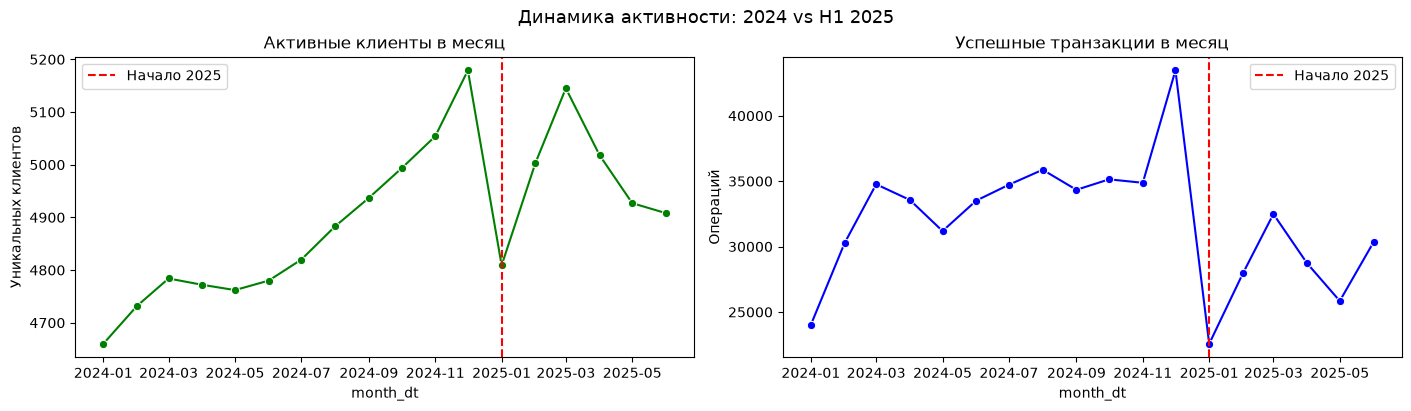

In [4]:
txn_success = txn[txn["status"] == "успешно"].copy()
txn_success["month"] = txn_success["txn_datetime"].dt.to_period("M")
monthly = (txn_success.groupby("month")
           .agg(clients=("client_id", "nunique"),
                txn=("txn_id", "count"))
           .reset_index())
monthly["month_dt"] = monthly["month"].dt.to_timestamp()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
sns.lineplot(data=monthly, x="month_dt", y="clients", marker="o",
             ax=axes[0], color="green")
axes[0].axvline(pd.Timestamp("2025-01-01"), color="red", ls="--",
                label="Начало 2025")
axes[0].set_title("Активные клиенты в месяц")
axes[0].set_ylabel("Уникальных клиентов"); axes[0].legend()

sns.lineplot(data=monthly, x="month_dt", y="txn", marker="o",
             ax=axes[1], color="blue")
axes[1].axvline(pd.Timestamp("2025-01-01"), color="red", ls="--",
                label="Начало 2025")
axes[1].set_title("Успешные транзакции в месяц")
axes[1].set_ylabel("Операций"); axes[1].legend()

fig.suptitle("Динамика активности: 2024 vs H1 2025", fontsize=13)
plt.show()

 За 1-ю половину 2025 в среднем 27 985 транзакций в месяц против 31 220 за 1-ю половину 2024 (−10,4 %). Активных клиентов при этом стало больше: 4 968 против 4 748 (+4,6 %). Новые клиенты приходят, но каждый из них платит реже — это и есть суть проблемы.

### 4.2. 

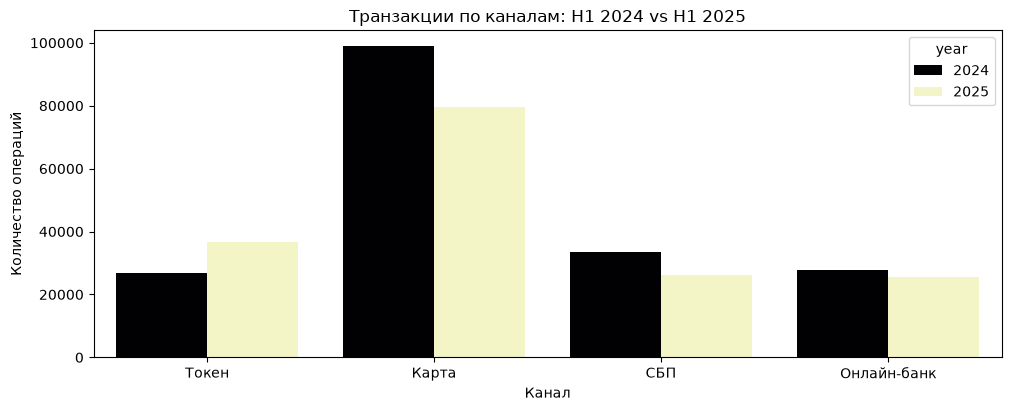

year          2024   2025      Δ
channel                         
Карта        99011  79519 -19492
Онлайн-банк  27932  25519  -2413
СБП          33536  26076  -7460
Токен        26839  36795   9956


In [5]:
txn_h1 = txn_success[txn_success["txn_datetime"].dt.month <= 6].copy()
txn_h1["year"] = txn_h1["txn_datetime"].dt.year

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
sns.countplot(data=txn_h1, x="channel", hue="year", ax=ax, palette="magma")
ax.set_title("Транзакции по каналам: H1 2024 vs H1 2025")
ax.set_xlabel("Канал"); ax.set_ylabel("Количество операций")
plt.show()

ch = (txn_h1.groupby(["channel", "year"], observed=True).size()
      .unstack(fill_value=0))
ch["Δ"] = ch[2025] - ch[2024]
print(ch)

«Карта» теряет около 20 тыс. операций в месяц — это основной источник падения. Рост «Токена» частично компенсирует.

### 4.3. 

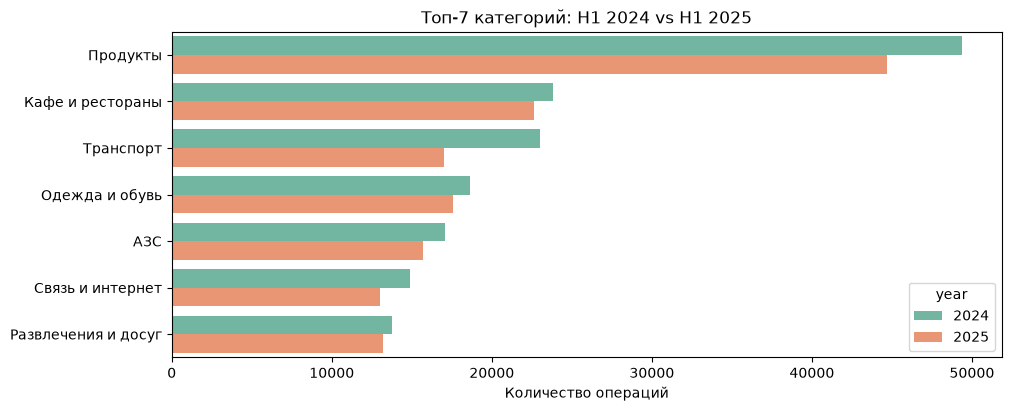

year                  2024   2025     Δ
category                               
Транспорт            22995  16992 -6003
Продукты             49388  44709 -4679
Связь и интернет     14904  12983 -1921
АЗС                  17068  15724 -1344
Кафе и рестораны     23809  22616 -1193
Одежда и обувь       18645  17590 -1055
Развлечения и досуг  13754  13178  -576


In [6]:
top_cat = txn_h1["category"].value_counts().head(7).index
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
sns.countplot(data=txn_h1[txn_h1["category"].isin(top_cat)],
              y="category", hue="year", ax=ax,
              order=top_cat, palette="Set2")
ax.set_title("Топ-7 категорий: H1 2024 vs H1 2025")
ax.set_xlabel("Количество операций"); ax.set_ylabel("")
plt.show()

by_cat = (txn_h1.groupby(["category", "year"], observed=True).size()
          .unstack(fill_value=0))
by_cat["Δ"] = by_cat[2025] - by_cat[2024]
print(by_cat.loc[top_cat].sort_values("Δ"))

Наибольшие абсолютные потери — «Продукты» и «Транспорт». Это ежедневные траты: клиенты перестают использовать нашу карту в супермаркетах и транспорте — вероятнее всего, из-за отсутствия кэшбэка или более выгодных условий у конкурентов именно в этих категориях.

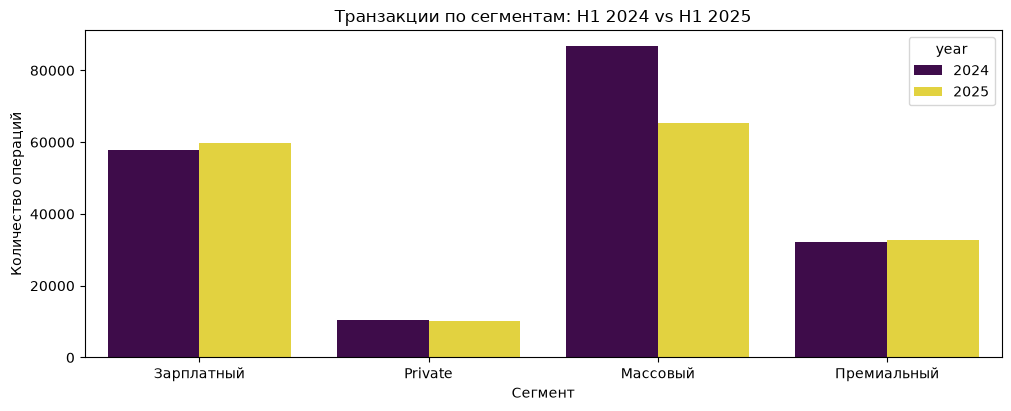

year          2024   2025    Δ%
segment                        
Массовый     86826  65265 -24.8
Private      10422  10259  -1.6
Премиальный  32114  32693   1.8
Зарплатный   57956  59692   3.0


In [7]:
clients_seg = clients.drop_duplicates("client_id")[["client_id", "segment"]]
txn_seg = txn_h1.merge(clients_seg, on="client_id", how="inner")

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
sns.countplot(data=txn_seg, x="segment", hue="year",
              ax=ax, palette="viridis")
ax.set_title("Транзакции по сегментам: H1 2024 vs H1 2025")
ax.set_xlabel("Сегмент"); ax.set_ylabel("Количество операций")
plt.show()

seg = (txn_seg.groupby(["segment", "year"], observed=True).size()
       .unstack(fill_value=0))
seg["Δ%"] = ((seg[2025] - seg[2024]) / seg[2024] * 100).round(1)
print(seg.sort_values("Δ%"))

Основное падение дают «Массовый» и «Зарплатный» сегменты. «Премиальный» и «Private» частоту операций сохранили. Это значит: чем выше доход, тем менее болезненно сказывается проблема — целевую аудиторию кампании нужно искать в массовом сегменте.

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->

In [8]:

txn_cardtok = txn[(txn["status"] == "успешно") &
                  (txn["channel"].isin(["Карта", "Токен"]))].copy()

base_2024 = txn_cardtok[(txn_cardtok["txn_datetime"] >= "2024-01-01") &
                        (txn_cardtok["txn_datetime"] <  "2025-01-01")]
h1_2025   = txn_cardtok[(txn_cardtok["txn_datetime"] >= "2025-01-01") &
                        (txn_cardtok["txn_datetime"] <  "2025-07-01")]

act = (base_2024.groupby("client_id").size().to_frame("txn_2024")
       .join(h1_2025.groupby("client_id").size().to_frame("txn_2025"),
             how="left")
       .fillna({"txn_2025": 0}))
act["avg_2024"] = act["txn_2024"] / 12
act["avg_2025"] = act["txn_2025"] / 6
act["drop_pct"] = (act["avg_2025"] - act["avg_2024"]) / act["avg_2024"] * 100

cli_u = clients.drop_duplicates("client_id").copy()
cli_u["age"] = (pd.Timestamp("2025-06-30") - cli_u["birth_date"]).dt.days // 365

tgt = act.reset_index().merge(
    cli_u[(cli_u["marketing_opt_in"] == "Да") &
          (cli_u["segment"] == "Массовый")],
    on="client_id", how="inner")
tgt = tgt[tgt["drop_pct"] < 0].copy()

tgt["group"] = np.select(
    [(tgt["has_mobile_app"] == "Нет"),
     ((tgt["gender"] == "Ж") & (tgt["age"] >= 59)) |
     ((tgt["gender"] == "М") & (tgt["age"] >= 64)),
     (tgt["loyalty_tier"] == "Базовый")],
    ["1_Без_приложения", "2_Пенсионеры", "3_Базовый"],
    default="4_Продвинутые")

print(tgt["group"].value_counts().sort_index())
print("Всего в кампании:", len(tgt))

group
1_Без_приложения    733
2_Пенсионеры        200
3_Базовый           578
4_Продвинутые       242
Name: count, dtype: int64
Всего в кампании: 1753


## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->

In [12]:
excl = pd.Series({
    "Клиенты без согласия на маркетинг":
        len(cli_u[cli_u["marketing_opt_in"] != "Да"]),
    "Не массовый сегмент (Private, Премиальный, Зарплатный)":
        len(cli_u[cli_u["segment"] != "Массовый"]),
    "Не имели активности в 2024":
        len(cli_u) - len(act),
    "Полностью перешли в Токен (карта = 0 в 2025)":
        int((tgt["txn_2025"] == 0).sum()),
}, name="n_clients")
print(excl.to_frame())

                                                    n_clients
Клиенты без согласия на маркетинг                         694
Не массовый сегмент (Private, Премиальный, Зарп...       2709
Не имели активности в 2024                                413
Полностью перешли в Токен (карта = 0 в 2025)               58


## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->

## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

In [14]:
import pandas as pd

cleaning_log = pd.read_csv("cleaning_log.csv")

display(cleaning_log[['field', 'issue', 'n_rows', 'action']].reset_index(drop=True))

,field,issue,n_rows,action
0,mcc_code,неинформативный признак (нет связи с category),624130,оставлено (исключено из анализа)
1,currency,наличие операций в USD (1146) и EUR (1134),2280,оставлено (ограничено для анализа сумм)
2,txn_datetime,строковый формат (с временем и без),624130,конвертация
3,"birth_date, registration_date, card_open_date,...",строковый формат на датах,5694,конвертация
4,category,"разнобой в написании, 12 уникальных значений в...",51801,исправлено
5,city,"разный регистр, приставки, сокращения (17 вари...",1685,нормализация
6,"cat_cols (segment, city, category и др.)",неоптимальный тип данных для полей с малым чис...,629824,изменение типа
7,app_last_login,пропуски 38.32%,2161,оставлено
8,monthly_income,пропуски 8.94%,504,заполнение
9,satisfaction_score,пропуски 60.12%,3390,создан флаг


### 8.2. Методика

**1. Окна сравнения**
- **Базовый период:** 01.01.2024 — 31.12.2024 (12 месяцев).
- **Оцениваемый период:** 01.01.2025 — 30.06.2025 (6 месяцев).

**2. Метрика активности**
Среднемесячное количество успешных транзакций на одного клиента. 
Считается как: `(Кол-во операций) / (Кол-во месяцев)`. 
Процент падения: `(Среднее 2025 - Среднее 2024) / Среднее 2024 * 100%`.

**3. Фильтры для транзакций**
В расчёт попадают только:
- Успешные операции (`status = 'успешно'`).
- Каналы «Карта» и «Токен» (суммарно, чтобы отличить реальное падение от простой смены пластика на телефон).
- Даты строго внутри периодов сравнения.

**4. Фильтры для клиентов**
В целевую аудиторию входят клиенты:
- Сегмент «Массовый».
- Согласие на маркетинг (`marketing_opt_in = 'Да'`).
- Имели хотя бы 1 операцию в 2024 году.
- Снижение активности (`drop_pct < 0`).

**5. Сегментация (правило приоритета 1 → 4)**
Клиент попадает ровно в одну группу по первому совпадению:
1. Без приложения (`has_mobile_app = 'Нет'`).
2. Пенсионеры (Ж от 59 лет, М от 64 лет).
3. Базовый уровень лояльности (`loyalty_tier = 'Базовый'`).
4. Продвинутые уровни (Серебро, Золото, Платина).

### 8.3. Использование ИИ

<!-- 3–5 строк: для чего использовали и что проверили сами. -->

Дипсик для написания кодов и составления отчета